In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, roc_curve, auc

# Cargar la base de datos de recursos humanos desde la liga de GitHub (con respaldo local)
url = "https://raw.githubusercontent.com/JoseRaulCastro/EBAC/main/recursos_humanos.csv"
try:
    data = pd.read_csv(url)
except Exception:
    data = pd.read_csv("recursos_humanos.csv")

print("Dimensiones:", data.shape)
data.head()

Dimensiones: (14999, 10)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [4]:
# Re-codificar las variables categóricas 'sales' y 'salary'
data_encoded = pd.get_dummies(data, columns=["sales", "salary"], dtype=float)

# Separar variable objetivo (y) y características (x_data)
y = data_encoded["left"].values
x_data = data_encoded.drop(["left"], axis=1)

print("Total de variables predictoras tras get_dummies:", x_data.shape[1])
x_data.head()

Total de variables predictoras tras get_dummies: 20


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_IT,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_high,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,0.80,0.86,5,262,6,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0.11,0.88,7,272,4,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3,0.72,0.87,5,223,5,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,0.37,0.52,2,159,3,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


In [5]:
# Revisar si la base está equilibrada según la variable objetivo 'left' (0 = permanece, 1 = baja)
print("Conteo por categoría en 'left':")
print(data["left"].value_counts())

print("\nProporción por categoría en 'left':")
print(data["left"].value_counts(normalize=True).round(4))

print("\nDistribución de 'salary':")
print(data["salary"].value_counts())

print("\nDistribución de 'sales':")
print(data["sales"].value_counts())

Conteo por categoría en 'left':
left
0    11428
1     3571
Name: count, dtype: int64

Proporción por categoría en 'left':
left
0    0.7619
1    0.2381
Name: proportion, dtype: float64

Distribución de 'salary':
salary
low       7316
medium    6446
high      1237
Name: count, dtype: int64

Distribución de 'sales':
sales
sales          4140
technical      2720
support        2229
IT             1227
product_mng     902
marketing       858
RandD           787
accounting      767
hr              739
management      630
Name: count, dtype: int64


In [6]:
# Normalización Min-Max (misma fórmula de Leccion 6.ipynb)
x = (x_data - np.min(x_data, axis=0)) / (np.max(x_data, axis=0) - np.min(x_data, axis=0))

# División 70% entrenamiento y 30% prueba
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.30, random_state=1)

print("Tamaño de entrenamiento:", x_train.shape[0])
print("Tamaño de prueba:", x_test.shape[0])

Tamaño de entrenamiento: 10499
Tamaño de prueba: 4500


In [7]:
resultados = []

for k in range(1, 21):
    knn_k = KNeighborsClassifier(n_neighbors=k)
    knn_k.fit(x_train, y_train)
    y_pred_k = knn_k.predict(x_test)
    cm_k = confusion_matrix(y_test, y_pred_k)

    # Precisiones siguiendo la lógica de la lección
    p_global = (cm_k[0, 0] + cm_k[1, 1]) / (cm_k[0, 0] + cm_k[1, 1] + cm_k[0, 1] + cm_k[1, 0])
    p_clase_0 = cm_k[0, 0] / (cm_k[0, 0] + cm_k[1, 0])
    p_clase_1 = cm_k[1, 1] / (cm_k[1, 1] + cm_k[0, 1])
    sens_1 = cm_k[1, 1] / (cm_k[1, 1] + cm_k[1, 0])

    y_scores_k = knn_k.predict_proba(x_test)
    fpr_k, tpr_k, _ = roc_curve(y_test, y_scores_k[:, 1])
    auc_k = auc(fpr_k, tpr_k)

    resultados.append({
        "k": k,
        "Precision_Global": round(p_global, 4),
        "Precision_Clase_0": round(p_clase_0, 4),
        "Precision_Clase_1": round(p_clase_1, 4),
        "Sensibilidad_Clase_1": round(sens_1, 4),
        "AUC": round(auc_k, 4)
    })

tabla_k = pd.DataFrame(resultados)
print(tabla_k.to_string(index=False))

C:\Users\emsb0\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\emsb0\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\emsb0\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\emsb0\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\emsb0\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _wina

 k  Precision_Global  Precision_Clase_0  Precision_Clase_1  Sensibilidad_Clase_1    AUC
 1            0.9618             0.9845             0.8958                0.9520 0.9585
 2            0.9578             0.9689             0.9217                0.9013 0.9644
 3            0.9453             0.9751             0.8600                0.9234 0.9660
 4            0.9460             0.9608             0.8978                0.8755 0.9679
 5            0.9393             0.9621             0.8690                0.8810 0.9666
 6            0.9447             0.9597             0.8957                0.8718 0.9664
 7            0.9411             0.9603             0.8802                0.8745 0.9662
 8            0.9393             0.9554             0.8866                0.8579 0.9649
 9            0.9324             0.9560             0.8585                0.8616 0.9633
10            0.9340             0.9535             0.8709                0.8524 0.9625
11            0.9293            

Matriz de confusión:
 [[3296  120]
 [  52 1032]]


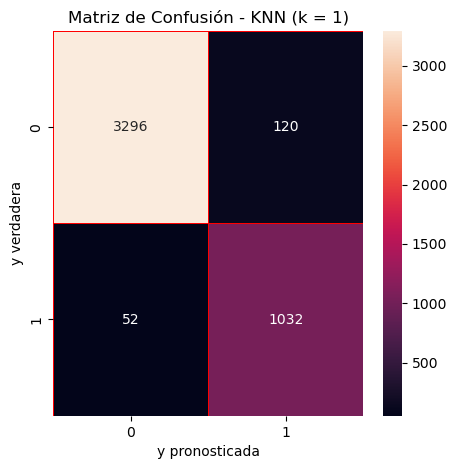

In [8]:
k_optimo = 1
knn = KNeighborsClassifier(n_neighbors=k_optimo)
knn.fit(x_train, y_train)
y_pred = knn.predict(x_test)

cm = confusion_matrix(y_test, y_pred)
print("Matriz de confusión:\n", cm)

f, ax = plt.subplots(figsize=(5, 5))
sns.heatmap(cm, annot=True, linewidths=0.5, linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("y pronosticada")
plt.ylabel("y verdadera")
plt.title(f"Matriz de Confusión - KNN (k = {k_optimo})")
plt.show()

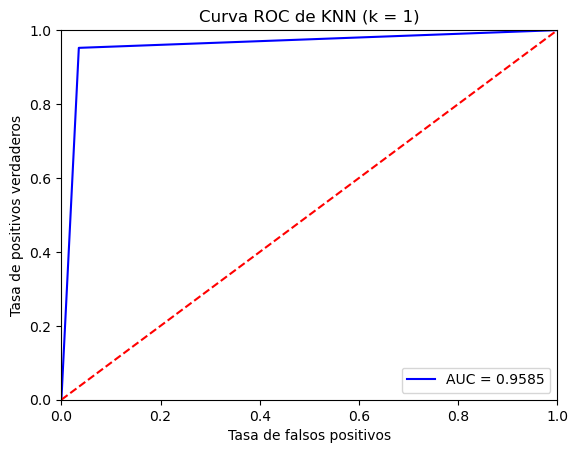

In [9]:
y_scores = knn.predict_proba(x_test)
fpr, tpr, threshold = roc_curve(y_test, y_scores[:, 1])
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, "b", label="AUC = %0.4f" % roc_auc)
plt.legend(loc="lower right")
plt.plot([0, 1], [0, 1], "r--")
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel("Tasa de positivos verdaderos")
plt.xlabel("Tasa de falsos positivos")
plt.title(f"Curva ROC de KNN (k = {k_optimo})")
plt.show()